In [ ]:
#imports the necessary lib

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Part 1: Load and Explore the Titanic Dataset

# Q1. Load & Inspect
1. Load the Titanic dataset using sns.load_dataset('titanic') and store it in a variable called df .
2. Print the shape of the dataset.
3. Display the first 6 rows.
4. Print the column names.


In [ ]:
# 1)
from seaborn import load_dataset
df = sns.load_dataset("titanic")

# 2)
print(df.shape)

# 3)
print(df.head(6))

# 4)
print(df.columns)

(891, 15)
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   
5         0       3    male   NaN      0      0   8.4583        Q  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
5    man        True  NaN   Queenstown    no   True  
Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'em

# Q2. Data Types & Missing Values
1. Use .info() to print column data types and non-null counts.
2. Print the number of missing values per column using .isnull().sum() .
3. Which column has the most missing values? 

In [ ]:
# 1)
df.info()

# 2)
print(df.isnull().sum())

# 3)
print(df.isnull().sum().idxmax())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB
survived         0
pclass           0
sex              0
age            177
sib

The columns with missing values are "age" and "deck".
The column with the most missing values is "deck".

# Q3. Basic Statistics
1. Use .describe() to display summary statistics for numeric columns.
2. From the output, answer in a Markdown cell:
 
   What is the mean age of passengers?
   
   What is the maximum fare paid?
   
   What percentage of passengers survived? (Hint: look at the survived mean, it represents the survival rate)

In [ ]:
# 1)
df.describe()


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


The mean age of passengers is approximately 29.7 years.  
    
The maximum fare paid is 512.33.  
    
The percentage of passengers who survived is about 38.38%.

# Q4. Duplicates & Categorical Summary
1. Check how many duplicate rows exist in the dataset.
2. Use .describe(include=['object', 'category']) to get a summary of categorical columns.
3. From the output, answer in a Markdown cell:
   
   What is the most common sex in the dataset and how many rows does it appear in?
   
   What is the most common embarkation port?

In [ ]:
# 1)
print(df.duplicated().sum())

# 2)
df.describe(include=['object', 'category'])



107


,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


The most common sex in the dataset is male, appearing 577 times.  
    
The most common embarkation port is S (Southampton).

# Part 2: Data Cleaning 

# Q5. Handle Missing Values
Create a new DataFrame called df_clean and apply the following cleaning steps in order:
1. Drop the deck column (too many missing values).
2. Fill missing values in the age column with the median age.
3. Fill missing values in the embarked column with the mode (most frequent value).
4. Fill missing values in the embark_town column with its mode.
5. After cleaning, print .isnull().sum() to confirm no missing values remain.


In [ ]:
df_clean = df.copy()

# 1)
df_clean.drop(columns = ["deck"], inplace = True)

age_median = df_clean["age"].mean()
embarked_mode = df_clean["embarked"].mode()[0]
embarkTowm_mode = df_clean["embark_town"].mode()[0]

# 2)
df_clean["age"].fillna(age_median, inplace = True)

# 3)
df_clean["embarked"].fillna(embarked_mode, inplace = True)

# 4)
df_clean["embark_town"].fillna(embarkTowm_mode, inplace = True)

# 5)
print(df_clean.isna().sum())

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


# Q6. Remove Duplicates & Redundant Columns
Continue working with df_clean :
1. Remove duplicate rows from df_clean using drop_duplicates(inplace=True) .
2. Drop the columns 'alive' and 'embark_town' - REASON - they are redundant (duplicated information from survived
and embarked ).
3. Print the shape before and after to show how many rows were removed. 

In [ ]:
# 1)
df_clean.drop_duplicates(inplace = True)

# 2)
df_clean.drop(columns = ["alive", "embark_town"], inplace = True)

# 3)
print(df_clean.shape)
print(df_clean.head())

(780, 12)
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male  alone  
0    man        True  False  
1  woman       False  False  
2  woman       False   True  
3  woman       False  False  
4    man        True   True  


# Q7. Outlier Detection
1. Create a boxplot for the fare column to visually identify outliers.
2. Use the IQR method to calculate the upper bound for outliers:
Q1 = fare.quantile(0.25) , Q3 = fare.quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
3. Print how many rows have a fare above the upper bound.
4. Create a new column fare_capped that clips the fare at the upper bound using .clip(upper=upper_bound) .

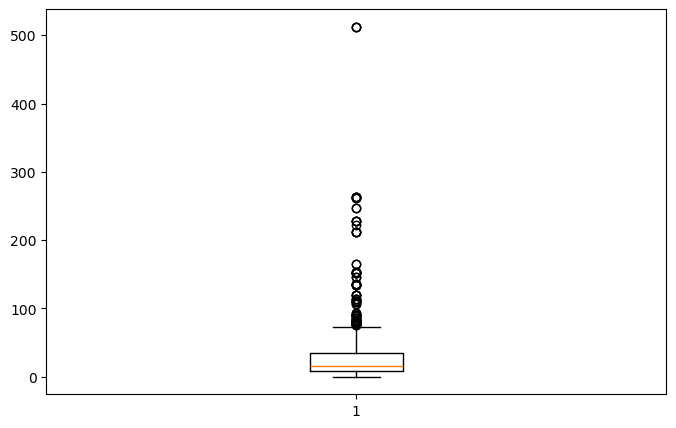

In [ ]:
# 1)
plt.figure(figsize=(8,5))
plt.boxplot(df_clean['fare'])

plt.show()

In [ ]:
# 2)
Q1 = df_clean['fare'].quantile(0.25)
Q3 = df_clean['fare'].quantile(0.75)

IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

print(upper_bound)

73.8625


In [ ]:
# 3)
print((df["fare"] > upper_bound).sum())

# 4)
df_clean["fare_capped"] = df_clean["fare"] .clip(upper=upper_bound)

97


# Part 3: Filtering, Sorting & Grouping


# Q8. Filtering
Using df_clean :
1. Filter passengers who survived ( survived == 1 ) AND were in First class ( class == 'First' ). How many are there?
2. Filter passengers who were older than 60. Print how many there are and display their names if the column exists, otherwise
display the filtered DataFrame.
3. Filter passengers who paid a fare above $50 and were female. How many rows match?

In [ ]:
# 1)
cond1 = (df_clean["survived"] == 1) & ( df["class"] == "First" )
df[cond1]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
11,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True
23,1,1,male,28.0,0,0,35.5000,S,First,man,True,A,Southampton,yes,True
31,1,1,female,NaN,1,0,146.5208,C,First,woman,False,B,Cherbourg,yes,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
862,1,1,female,48.0,0,0,25.9292,S,First,woman,False,D,Southampton,yes,True
871,1,1,female,47.0,1,1,52.5542,S,First,woman,False,D,Southampton,yes,False
879,1,1,female,56.0,0,1,83.1583,C,First,woman,False,C,Cherbourg,yes,False
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True


In [ ]:
# 2)
cond2 = (df_clean["age"]>60)
print(df_clean[cond2].shape[0])

if "name" in df_clean.columns:
    print(df_clean[cond2]["name"].tolist())
else:
    print(df_clean[cond2])

21
     survived  pclass     sex   age  sibsp  parch      fare embarked   class  \
33          0       2    male  66.0      0      0   10.5000        S  Second   
54          0       1    male  65.0      0      1   61.9792        C   First   
96          0       1    male  71.0      0      0   34.6542        C   First   
116         0       3    male  70.5      0      0    7.7500        Q   Third   
170         0       1    male  61.0      0      0   33.5000        S   First   
252         0       1    male  62.0      0      0   26.5500        S   First   
275         1       1  female  63.0      1      0   77.9583        S   First   
280         0       3    male  65.0      0      0    7.7500        Q   Third   
326         0       3    male  61.0      0      0    6.2375        S   Third   
438         0       1    male  64.0      1      4  263.0000        S   First   
456         0       1    male  65.0      0      0   26.5500        S   First   
483         1       3  female  63.0  

In [ ]:
# 3)
cond3 = (df_clean['fare'] > 50) & (df_clean['sex'] == 'female')
print(df_clean[cond3].shape[0])

84


# Q9. Sorting
Using df_clean :
1. Sort the DataFrame by fare in descending order and display the top 5 rows (only columns: sex , age , class , fare ,
survived ).
2. Sort by age in ascending order and display the 5 youngest passengers.
3. In a Markdown cell, state one observation from each sorted result.

In [ ]:
# 1)
top_fares = df_clean.sort_values(by="fare", ascending=False)[["sex", "age", "class", "fare", "survived"]].head(5)
print(top_fares)

# 2)
youngest_passengers = df_clean.sort_values(by="age", ascending=True)[["sex", "age", "class", "fare", "survived"]].head(5)
print(youngest_passengers)


        sex   age  class      fare  survived
737    male  35.0  First  512.3292         1
258  female  35.0  First  512.3292         1
679    male  36.0  First  512.3292         1
341  female  24.0  First  263.0000         1
27     male  19.0  First  263.0000         0
        sex   age   class     fare  survived
803    male  0.42   Third   8.5167         1
755    male  0.67  Second  14.5000         1
469  female  0.75   Third  19.2583         1
831    male  0.83  Second  18.7500         1
78     male  0.83  Second  29.0000         1


Top fares: The passengers who paid the highest fares are mostly in First class, and most of them survived.

Youngest passengers: The youngest passengers are infants or very young children, often traveling in Third class or with family.

# Q10. GroupBy & Aggregation
Using df_clean :
1. Use .groupby('sex')['survived'].mean() to find the survival rate by sex. Round to 2 decimal places.
2. Use .groupby('class')['survived'].mean() to find the survival rate by passenger class.
3. Use .groupby('class')['fare'].mean() to find the average fare per class.
4. In a Markdown cell, write two observations from the results above.


In [ ]:
# 1)
by_sex = df_clean.groupby('sex')['survived'].mean().round(2)
print(by_sex)

# 2)
by_class= df_clean.groupby('class')['survived'].mean().round(2)
print(by_class)

# 3)
avg_fare = df_clean.groupby('class')['fare'].mean().round(2)
print(avg_fare)

sex
female    0.74
male      0.22
Name: survived, dtype: float64
class
First     0.64
Second    0.51
Third     0.26
Name: survived, dtype: float64
class
First     85.16
Second    21.89
Third     13.67
Name: fare, dtype: float64


Survival by sex: Females had a much higher survival rate than males, indicating gender played a key role in survival.
    
Class and fare: Passengers in First class had higher survival rates and also paid significantly higher fares on average,
suggesting class influenced both survival chances and ticket price.

# Part 4: Visualization


# Q11. Histogram & Count Plot
Create a figure with two subplots side by side ( figsize=(12, 4) ):

Left subplot: Histogram of age using sns.histplot with kde=True and bins=20 . Title: 'Age Distribution' .

Right subplot: Count plot of survived using sns.countplot . Title: 'Survival Count' .

Use plt.tight_layout() and plt.show() .

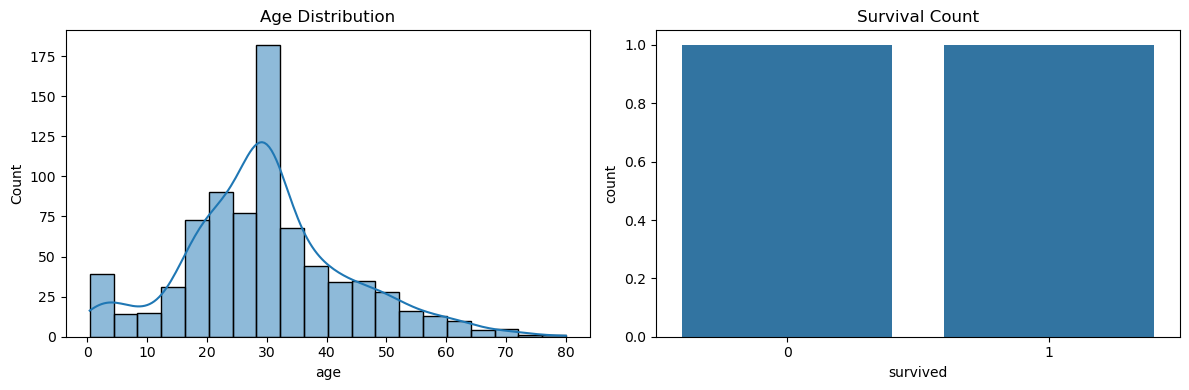

In [ ]:
plt.figure(figsize = (12,4))

plt.subplot(1,2,1)
sns.histplot(data = df_clean, x = "age", kde = True, bins = 20)
plt.title('Age Distribution')

plt.subplot(1,2,2)
sns.countplot(data = df_clean["survived"].value_counts())
plt.title('Survival Count')

plt.tight_layout()
plt.show()

# Q12. Categorical Plots
Create a figure with two subplots side by side ( figsize=(12, 5) ):

Left: sns.countplot with x='sex' and hue='survived' . Title: 'Survival by Sex' .

Right: sns.countplot with x='class' and hue='survived' . Title: 'Survival by Class' .

In a Markdown cell below, interpret each plot in one sentence each.

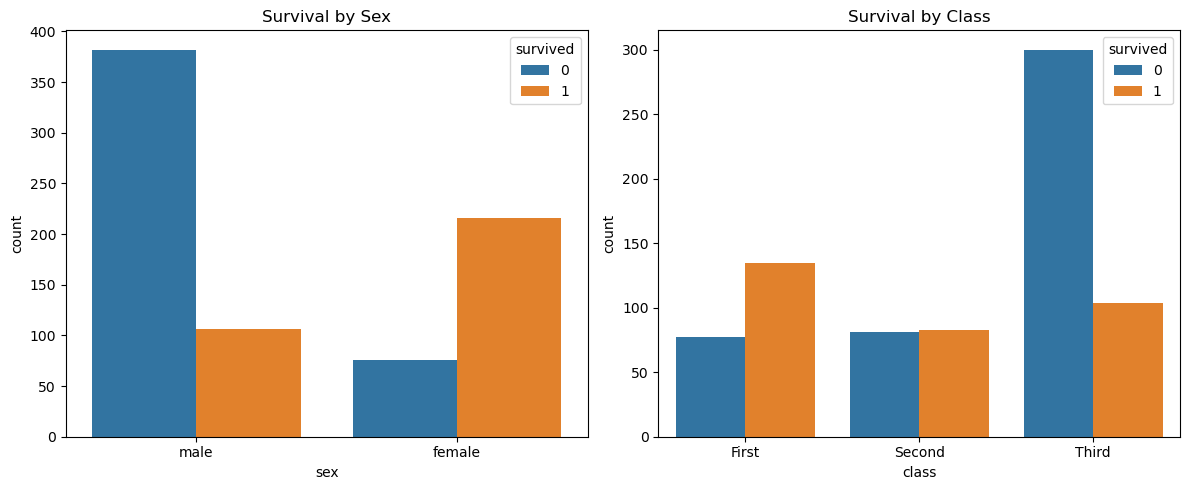

In [ ]:
plt.figure(figsize = (12,5))

plt.subplot(1,2,1)
sns.countplot(data = df_clean, x = "sex", hue = "survived")
plt.title('Survival by Sex')

plt.subplot(1,2,2)
sns.countplot(data = df_clean, x='class', hue='survived')
plt.title('Survival by Class')

plt.tight_layout()
plt.show()

## Survival by Sex

Females had a much higher survival rate than males. Most female passengers survived, while the majority of male passengers did not.

This shows that gender played a major role in survival chances, likely due to the “women and children first” policy.
    
## Survival by Class

First-class passengers had the highest survival rate, followed by Second class, while Third-class passengers had the lowest survival rate.

This indicates that passenger class strongly influenced survival, with wealthier passengers having better access to lifeboats and safety.

# Q13. Boxplot & Scatter Plot
1. Create a boxplot using sns.boxplot(x='class', y='age', hue='survived', data=df_clean) . Title: 'Age by Class
and Survival' .

3. Create a scatter plot using sns.scatterplot(x='age', y='fare_capped', hue='survived', data=df_clean,
alpha=0.6) . Title: 'Age vs Fare (Capped) by Survival' .


5. In a Markdown cell, write one observation from each plot.

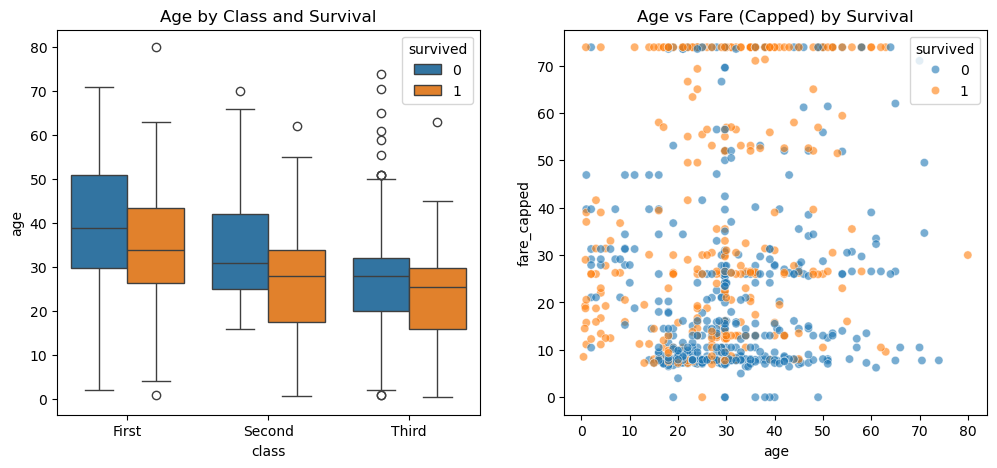

In [ ]:
plt.figure(figsize = (12,5))

plt.subplot(1,2,1)
sns.boxplot(x = "class", y = "age",  hue = "survived", data = df_clean)
plt.title('Age by Class and Survival')

plt.subplot(1,2,2)
sns.scatterplot(x='age', y='fare_capped', hue='survived', data = df_clean, alpha=0.6)
plt.title('Age vs Fare (Capped) by Survival')

plt.show()

Age by Class and Survival (Boxplot):

Younger passengers in First and Second class had higher survival rates,
while Third-class passengers included more older passengers who did not survive.

Age vs Fare (Capped) by Survival (Scatterplot):

Passengers who paid higher fares (mostly in First class) and were younger had a higher likelihood of survival,
while lower fares correlate with lower survival.

# Q14. Correlation Heatmap
1. Select all numeric columns from df_clean using select_dtypes(include=np.number) .
2. Compute the correlation matrix using .corr() .
3. Plot it as a heatmap using sns.heatmap(... annot=True, cmap='coolwarm', center=0) . Set figsize=(8, 6) . Title:
'Correlation Heatmap' .
4. In a Markdown cell, identify the two features most positively correlated with survival.

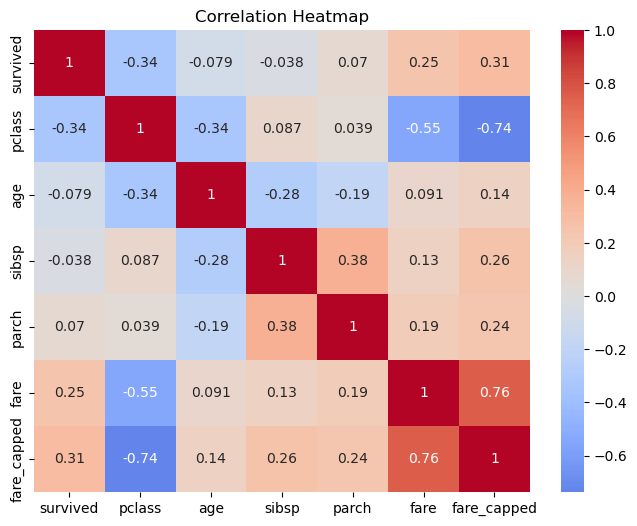

In [ ]:
# 1)
numeric = df_clean.select_dtypes(include=np.number)

# 2)
matrix = numeric.corr()

# 3)
plt.figure(figsize = (8,6))
sns.heatmap(data = matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

fare (or fare_capped) passengers who paid higher fares tended to survive more. pclass reversed as numeric – often,

First class passengers (lower numeric class number) had higher survival,

so class is positively correlated when interpreted accordingly.

# Part 5: Tips Dataset: Filtering & Grouping


# Q15. Load and Filter the Tips Dataset
1. Load the tips dataset: tips = sns.load_dataset('tips') .
2. Display the first 5 rows and print the shape.
3. Filter only dinner orders where the total bill is above $20. How many rows match?
4. From those filtered rows, find the average tip.

In [ ]:
# 1)
tips = sns.load_dataset("tips")

# 2)
print(tips.head())
print(tips.shape)

# 3)
filtered = tips[(tips["time"] == "Dinner") & (tips["total_bill"] > 20)]
print(filtered.shape[0])

# 4)
avg_tip = filtered["tip"].mean()
print(avg_tip)

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
(244, 7)
81
3.8858024691358026


# Q16. Grouping the Tips Dataset
Using the full tips DataFrame:
1. Use .groupby('day')['tip'].mean() to find the average tip by day. Sort from highest to lowest.
2. Use .groupby('smoker')['tip'].mean() to compare tips between smokers and non-smokers.
3. In a Markdown cell, answer: Do smokers tip more or less on average?

In [ ]:
# 1) 
avg_tip_by_day = tips.groupby('day')['tip'].mean().sort_values(ascending=False)
print(avg_tip_by_day)

# 2)
avg_tip_by_smoker = tips.groupby('smoker')['tip'].mean()
print(avg_tip_by_smoker)

day
Sun     3.255132
Sat     2.993103
Thur    2.771452
Fri     2.734737
Name: tip, dtype: float64
smoker
Yes    3.008710
No     2.991854
Name: tip, dtype: float64


Smokers tip slightly less on average than non-smokers, according to the dataset.

# Q17. Visualize the Tips Dataset
Create a figure with three subplots ( figsize=(15, 4) ):

Left: Scatter plot of total_bill vs tip (use plt.scatter ). Title: 'Tip vs Total Bill' .

Center: Bar plot of average tip by day (use .plot(kind='bar') on the grouped result). Title: 'Average Tip by Day' .

Right: Histogram of tip with bins=15 and edgecolor='k' . Title: 'Tip Distribution' .

Add axis labels and plt.tight_layout() .

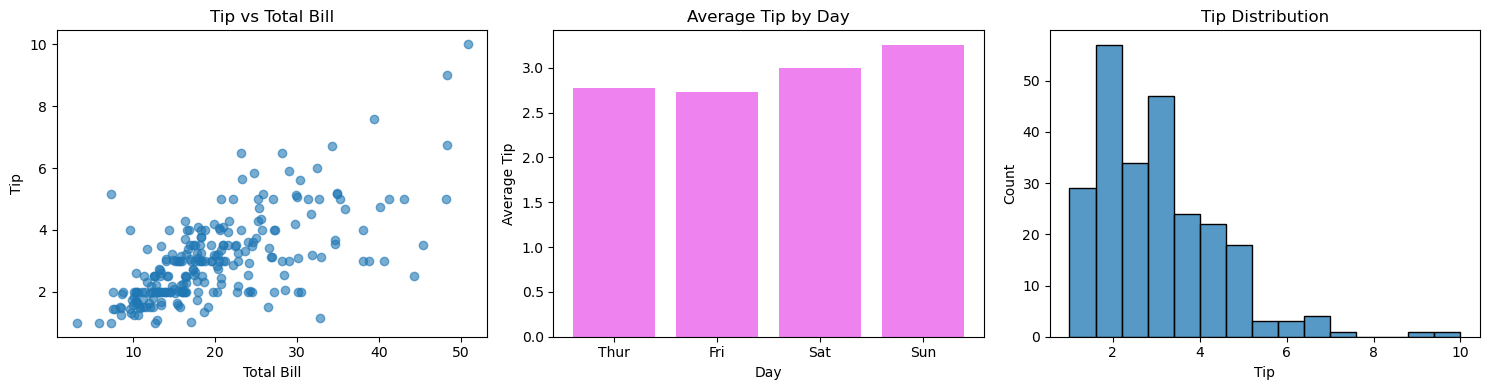

In [ ]:
plt.figure(figsize = (15,4))

plt.subplot(1,3,1)
plt.scatter(tips['total_bill'], tips['tip'], alpha=0.6)
plt.title('Tip vs Total Bill')
plt.xlabel('Total Bill')
plt.ylabel('Tip')
                                                                    
plt.subplot(1,3,2)
plt.bar(avg_tip_by_day.index, avg_tip_by_day.values, color='violet')
plt.title('Average Tip by Day')
plt.xlabel('Day')
plt.ylabel('Average Tip')

plt.subplot(1,3,3)
sns.histplot(data=tips, x='tip', bins=15, edgecolor='k')
plt.title('Tip Distribution')
plt.xlabel('Tip')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

# Linear Regression on Tips
Using the tips dataset:
1. Extract X = total_bill (reshape to column: tips[['total_bill']].values ) and y = tip
( tips[['tip']].values ).
2. Train a LinearRegression model from sklearn.linear_model .
3. Print the coefficient and intercept. Interpret them in a sentence: "For every extra 1 dollar on the bill, the tip increases by..."
4. Plot the data as a scatter plot and overlay the regression line in red.
5. Predict the tip for a total bill of $30.


0.10502451738435335
0.9202696135546735
For every extra 1 dollar on the bill, the tip increases by $0.10502451738435335 on average.


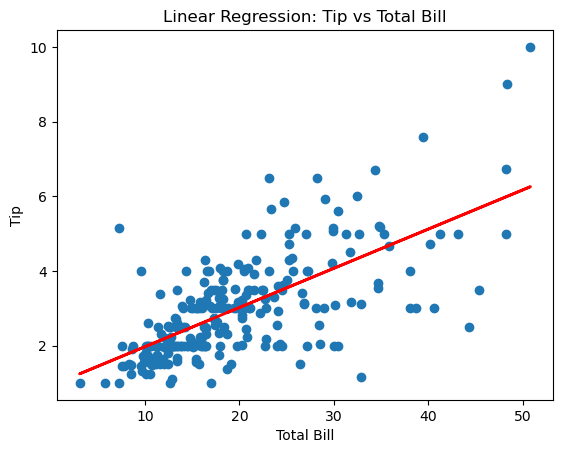

4.071005135085274


In [ ]:
# 1)
X = tips[['total_bill']].values
y = tips[['tip']].values

# 2)
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X, y)

# 3)
coeff = model.coef_[0][0]
intercept = model.intercept_[0]

print(coeff)
print(intercept)
print(f"For every extra 1 dollar on the bill, the tip increases by ${coef} on average.")

# 4)
y_pred = model.predict(X)
plt.scatter(X, y)
plt.plot(X, y_pred, color = "r", linewidth = 2)
plt.title('Linear Regression: Tip vs Total Bill')
plt.xlabel('Total Bill')
plt.ylabel('Tip')
plt.show()

# 5)
cost = [[30]]
y_pred = model.predict(cost)[0][0]
print(y_pred)